
# Step 5-2. Multimodal T2D Prediction — TabPFN

## 1. Overview

This notebook demonstrates participant-level type 2 diabetes (T2D) prediction using TabPFN, a pretrained tabular foundation model.

The model uses 4,100 predictors prepared in Step 4, integrating medical imaging features, demographic and clinical characteristics, and polygenic risk scores (PRS).

| Feature source | Number of predictors |
|---|---:|
| ABD-US GNN activation vectors | 1,024 |
| BMD left hip DenseNet121 activation vectors | 1,024 |
| BMD right hip DenseNet121 activation vectors | 1,024 |
| BMD spine DenseNet121 activation vectors | 1,024 |
| Age, sex, and family history | 3 |
| Combined PRS-CSx score | 1 |
| **Total** | **4,100** |

The combined PRS-CSx score is calculated using predefined equal ancestry coefficients (1:1:1) and rescaled using Min-Max scaling parameters estimated from Training1 and Training2, as described in Step 4.

This notebook uses the pretrained TabPFN foundation model. Fitting the demonstration dataset does not update the underlying foundation-model weights.

## 2. Dataset Partition

The demonstration dataset contains 100 participants divided into four mutually exclusive subsets.

| Dataset | Participants | Purpose |
|---|---:|---|
| Training1 | 32 | Previously used for DenseNet training; excluded from TabPFN fitting |
| Training2 | 32 | TabPFN in-context support dataset |
| Validation | 16 | Classification threshold selection using the maximum Youden Index |
| Testing | 20 | Final model evaluation |

The TabPFN support dataset contains only Training2 participants.

Validation is used to determine the classification threshold. Testing is excluded from model fitting, threshold selection, and parameter tuning.

## 3. Model Architecture and Hyperparameters

| Hyperparameter | Original implementation | GitHub demo |
|---|---|---|
| Architecture | TabPFN classifier | TabPFN classifier |
| TabPFN version | 2.2.1 | **2.2.1** |
| Foundation-model weights | Pretrained | Pretrained |
| Support dataset | Training2 | Training2 |
| Number of estimators | 8 | **8** |
| Fit mode | low_memory | **low_memory** |
| Memory saving mode | auto | **auto** |
| Ignore pretraining limits | True | **True** |
| Task-specific weight updates | None | None |
| Early stopping | Not used | Not used |
| Classification threshold | Default probability-based classification | **Maximum Validation Youden Index** |
| Final evaluation | Testing | Testing |

All user-adjustable parameters are defined at the beginning of the Python code.

TabPFN 2.2.1 is used to preserve the study's software implementation. Because the demonstration contains 4,100 predictors, `ignore_pretraining_limits=True` is used to permit execution beyond the model's recommended pretraining feature range.

This setting does not guarantee equivalent performance outside the original pretraining range. TabPFN may also internally subsample features across ensemble members.

## 4. Threshold Selection

The optimal classification threshold is selected by maximizing the Youden Index on Validation:

**Youden Index = Sensitivity + Specificity − 1**

The threshold is selected from the observed Validation ROC thresholds rather than an approximate threshold grid.

If multiple thresholds yield the same maximum Youden Index, the highest threshold is selected.

The selected threshold is applied unchanged to the Testing dataset.

Testing labels are not used to select or modify the classification threshold.

## 5. Model Evaluation

Both Validation and Testing are evaluated using:

| Metric | Description |
|---|---|
| AUC | Area under the ROC curve |
| Accuracy | Overall classification accuracy |
| Sensitivity | True positive rate (Recall) |
| Specificity | True negative rate |
| Precision | Positive predictive value (PPV) |
| NPV | Negative predictive value |
| F1 Score | Harmonic mean of precision and recall |
| Youden Index | Sensitivity + Specificity − 1 |
| Average Precision | Summary of precision–recall performance |
| Brier Score | Mean squared error of predicted probabilities |

Confusion matrices are generated separately for Validation and Testing and include true negatives (TN), false positives (FP), false negatives (FN), and true positives (TP).

AUC, Average Precision, and Brier Score are computed from predicted probabilities and are independent of the selected classification threshold.

The Validation results are used for threshold selection and therefore are not an independent estimate of model performance.

Due to the small demonstration sample size, these metrics are intended to demonstrate the reproducible analysis workflow rather than estimate the performance of the original study.

## 6. Outputs

All generated files are saved under:

`Outputs/Step5_TabPFN/`

The notebook produces:

1. TabPFN run configuration.
2. Validation ROC thresholds and Youden Index values.
3. Participant-level predicted probabilities and predicted labels.
4. Validation and Testing evaluation metrics.
5. Validation and Testing confusion matrices.

A study-specific neural-network checkpoint is not provided because fitting TabPFN on the demonstration dataset does not update the pretrained foundation-model weights.



## Environment Setup

This notebook requires TabPFN 2.2.1, PyTorch, NumPy, pandas, scikit-learn, and Matplotlib.

The software environment is defined in `environments/gpu.yml`.

### 1. Create the environment

From the downloaded repository root, run:

```bash
conda env create -f environments/gpu.yml
```

If the `t2d-gpu` environment already exists but TabPFN has not been installed, run:

```bash
conda run -n t2d-gpu python -m pip install tabpfn==2.2.1
```

### 2. Register the Jupyter Kernel

```bash
conda run -n t2d-gpu python -m ipykernel install \
    --user \
    --name t2d-gpu \
    --display-name "T2D GPU"
```

### 3. Select the Kernel

Open this notebook in JupyterLab or Jupyter Notebook and select:

**Kernel → Change Kernel → T2D GPU**

### 4. Pretrained Foundation-Model Weights

TabPFN requires pretrained foundation-model weights that may be downloaded during initial model initialization.

Internet access may be required, and users must comply with the applicable model-weight license.

The pretrained model weights are separate from the demonstration dataset and are not generated by the fitting procedure in this notebook.

### 5. Prerequisite Data

Complete the previous DenseNet, GNN, and feature-assembly notebooks.

The following input file must exist:

`Outputs/Step4_Feature_Assembly/Multimodal_100_samples_PRSCSx_EqualWeight.csv`

This file contains 100 participants, 4,100 predictors, and three additional metadata columns.

No package installation is performed inside the Python analysis cells.


In [2]:
# ============================================================
# 0. TabPFN — Configuration and Data Preparation
# ============================================================

from pathlib import Path
import json
import time
import platform

import numpy as np
import pandas as pd
import torch
import tabpfn

from tabpfn import TabPFNClassifier


# ============================================================
# 0.1 Project Paths
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()

INPUT_FILE = (
    PROJECT_ROOT
    / "Outputs/Step4_Feature_Assembly"
    / "Multimodal_100_samples_PRSCSx_EqualWeight.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "Outputs/Step5_TabPFN"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_FILE = (
    OUTPUT_DIR / "TabPFN_RunConfig.json"
)

THRESHOLD_FILE = (
    OUTPUT_DIR / "TabPFN_ValidationThresholds.csv"
)

PREDICTION_FILE = (
    OUTPUT_DIR / "TabPFN_Predictions.csv"
)

METRICS_FILE = (
    OUTPUT_DIR / "TabPFN_EvaluationMetrics.csv"
)


# ============================================================
# 0.2 User-defined Hyperparameters
# ============================================================

MODEL_NAME = "TabPFN"

EXPECTED_TABPFN_VERSION = "2.2.1"

RANDOM_SEED = 1

# TabPFN ensemble
N_ESTIMATORS = 8

# Memory configuration
FIT_MODE = "low_memory"
MEMORY_SAVING_MODE = "auto"

# Required for this 4,100-feature demonstration
IGNORE_PRETRAINING_LIMITS = True

# Classification threshold
THRESHOLD_METHOD = "max_youden"
THRESHOLD_SELECTION_SPLIT = "validation"

# When multiple thresholds have the same maximum Youden:
# select the highest threshold.
THRESHOLD_TIE_BREAK = "highest"

# ------------------------------------------------------------
# GPU configuration
# ------------------------------------------------------------

GPU_INDEX = 0

USE_GPU = True
ALLOW_CPU_FALLBACK = True


# ============================================================
# 0.3 Reproducibility
# ============================================================

np.random.seed(RANDOM_SEED)

torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)


# ============================================================
# 0.4 Device Selection
# ============================================================

if USE_GPU and torch.cuda.is_available():

    if GPU_INDEX >= torch.cuda.device_count():
        raise ValueError(
            f"GPU_INDEX={GPU_INDEX} is unavailable. "
            f"Visible GPUs: {torch.cuda.device_count()}"
        )

    DEVICE = f"cuda:{GPU_INDEX}"

elif ALLOW_CPU_FALLBACK:

    DEVICE = "cpu"

else:

    raise RuntimeError(
        "CUDA is unavailable and CPU fallback is disabled."
    )


# ============================================================
# 0.5 Verify Software Environment
# ============================================================

assert tabpfn.__version__ == EXPECTED_TABPFN_VERSION, (
    f"Expected TabPFN {EXPECTED_TABPFN_VERSION}, "
    f"found {tabpfn.__version__}"
)

assert INPUT_FILE.is_file(), (
    f"Input file not found: {INPUT_FILE}"
)


# ============================================================
# 0.6 Load Participant-level Feature Data
# ============================================================

df = pd.read_csv(
    INPUT_FILE,
    dtype={"Demo_ID": str}
)

META_COLUMNS = [
    "Demo_ID",
    "Dataset",
    "T2D",
]

FEATURE_COLUMNS = [
    col for col in df.columns
    if col not in META_COLUMNS
]

EXPECTED_SPLITS = {
    "training1": 32,
    "training2": 32,
    "validation": 16,
    "testing": 20,
}

assert len(df) == 100
assert df.shape == (100, 4103)

assert len(FEATURE_COLUMNS) == 4100

assert df["Demo_ID"].is_unique

assert len(FEATURE_COLUMNS) == len(
    set(FEATURE_COLUMNS)
)

df["Dataset"] = (
    df["Dataset"]
    .astype(str)
    .str.strip()
    .str.lower()
)

assert (
    df["Dataset"].value_counts().to_dict()
    == EXPECTED_SPLITS
)

df["T2D"] = pd.to_numeric(
    df["T2D"],
    errors="raise"
).astype(int)

assert set(df["T2D"].unique()) <= {0, 1}


# ============================================================
# 0.7 Verify Predictors
# ============================================================

df[FEATURE_COLUMNS] = (
    df[FEATURE_COLUMNS]
    .apply(pd.to_numeric, errors="raise")
    .astype(np.float32)
)

assert np.isfinite(
    df[FEATURE_COLUMNS].to_numpy()
).all()

assert "PRS_Score" in FEATURE_COLUMNS

assert df["PRS_Score"].between(0, 1).all()

# Avoid accidental inclusion of metadata / outcome
assert not (
    set(META_COLUMNS) & set(FEATURE_COLUMNS)
)


# ============================================================
# 0.8 Prepare Dataset Partitions
# ============================================================

def get_split(split_name):

    subset = (
        df.loc[
            df["Dataset"] == split_name
        ]
        .sort_values("Demo_ID")
        .reset_index(drop=True)
    )

    X = subset[
        FEATURE_COLUMNS
    ].to_numpy(dtype=np.float32)

    y = subset[
        "T2D"
    ].to_numpy(dtype=int)

    return subset, X, y


df_train, X_train, y_train = get_split("training2")

df_valid, X_valid, y_valid = get_split("validation")

df_test, X_test, y_test = get_split("testing")


# ============================================================
# 0.9 Verify Splits
# ============================================================

assert X_train.shape == (32, 4100)
assert X_valid.shape == (16, 4100)
assert X_test.shape == (20, 4100)

for name, labels in [
    ("Training2", y_train),
    ("Validation", y_valid),
    ("Testing", y_test),
]:

    assert set(np.unique(labels)) == {0, 1}, (
        f"{name} must contain both T2D classes."
    )

train_ids = set(df_train["Demo_ID"])
valid_ids = set(df_valid["Demo_ID"])
test_ids = set(df_test["Demo_ID"])

assert train_ids.isdisjoint(valid_ids)
assert train_ids.isdisjoint(test_ids)
assert valid_ids.isdisjoint(test_ids)


# ============================================================
# 0.10 Display Configuration
# ============================================================

print("=" * 65)
print("TABPFN — DEMONSTRATION CONFIGURATION")
print("=" * 65)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("TabPFN:", tabpfn.__version__)

print("\nModel configuration")
print("N estimators:", N_ESTIMATORS)
print("Fit mode:", FIT_MODE)
print("Memory saving:", MEMORY_SAVING_MODE)

print(
    "Ignore pretraining limits:",
    IGNORE_PRETRAINING_LIMITS
)

print("\nClassification threshold")
print("Method:", THRESHOLD_METHOD)
print("Selection dataset:", THRESHOLD_SELECTION_SPLIT)
print("Tie-breaking rule:", THRESHOLD_TIE_BREAK)

print("\nComputational device")
print("Device:", DEVICE)

if DEVICE.startswith("cuda"):
    print(
        "GPU:",
        torch.cuda.get_device_name(GPU_INDEX)
    )

print("\nInput data")
print("Total participants:", len(df))
print("Number of predictors:", len(FEATURE_COLUMNS))

print("Training2:", X_train.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)

print("\nClass distribution:")

display(
    pd.crosstab(
        df["Dataset"],
        df["T2D"]
    ).reindex(
        list(EXPECTED_SPLITS.keys())
    )
)

print("\nTabPFN configuration completed.")

TABPFN — DEMONSTRATION CONFIGURATION
Python: 3.11.18
PyTorch: 2.7.1+cu128
TabPFN: 2.2.1

Model configuration
N estimators: 8
Fit mode: low_memory
Memory saving: auto
Ignore pretraining limits: True

Classification threshold
Method: max_youden
Selection dataset: validation
Tie-breaking rule: highest

Computational device
Device: cuda:0
GPU: NVIDIA A100-SXM4-40GB

Input data
Total participants: 100
Number of predictors: 4100
Training2: (32, 4100)
Validation: (16, 4100)
Testing: (20, 4100)

Class distribution:


T2D,0,1
Dataset,,
training1,16,16
training2,16,16
validation,8,8
testing,10,10



TabPFN configuration completed.


In [3]:
# ============================================================
# 1. TabPFN — Fit and Validation Probability Prediction
# ============================================================


# ============================================================
# 1.1 Initialize Pretrained TabPFN
# ============================================================

model = TabPFNClassifier(
    n_estimators=N_ESTIMATORS,
    device=DEVICE,
    fit_mode=FIT_MODE,
    memory_saving_mode=MEMORY_SAVING_MODE,
    ignore_pretraining_limits=IGNORE_PRETRAINING_LIMITS,
    random_state=RANDOM_SEED,
)


# ============================================================
# 1.2 Fit Using Training2 Only
# ============================================================

if DEVICE.startswith("cuda"):
    torch.cuda.reset_peak_memory_stats(
        torch.device(DEVICE)
    )

fit_start = time.perf_counter()

model.fit(
    X_train,
    y_train
)

FIT_SECONDS = (
    time.perf_counter() - fit_start
)


# ============================================================
# 1.3 Determine Positive Class Index
# ============================================================

model_classes = np.asarray(
    model.classes_
).astype(int)

assert set(model_classes.tolist()) == {0, 1}

POSITIVE_CLASS_INDEX = int(
    np.where(model_classes == 1)[0][0]
)


# ============================================================
# 1.4 Predict Validation Probabilities
# ============================================================

valid_start = time.perf_counter()

valid_prob_all = model.predict_proba(
    X_valid
)

VALID_INFERENCE_SECONDS = (
    time.perf_counter() - valid_start
)

assert valid_prob_all.shape == (16, 2)

valid_prob = valid_prob_all[
    :, POSITIVE_CLASS_INDEX
].astype(float)


# ============================================================
# 1.5 Verify Probabilities
# ============================================================

assert np.isfinite(valid_prob).all()

assert np.all(
    (valid_prob >= 0) & (valid_prob <= 1)
)


# ============================================================
# 1.6 Display Summary
# ============================================================

print("=" * 65)
print("TABPFN VALIDATION PREDICTION COMPLETED")
print("=" * 65)

print("Training2 support participants:", len(X_train))
print("Validation participants:", len(X_valid))

print("\nFit seconds:", round(FIT_SECONDS, 3))

print(
    "Validation inference seconds:",
    round(VALID_INFERENCE_SECONDS, 3)
)

print("\nValidation probability range:")
print(
    round(float(valid_prob.min()), 6),
    "to",
    round(float(valid_prob.max()), 6)
)

display(
    pd.DataFrame({
        "Demo_ID": df_valid["Demo_ID"],
        "T2D": y_valid,
        "Predicted_Probability": valid_prob,
    }).head(10)
)

print("\nReady for Maximum Youden threshold selection.")

TABPFN VALIDATION PREDICTION COMPLETED
Training2 support participants: 32
Validation participants: 16

Fit seconds: 2.993
Validation inference seconds: 5.995

Validation probability range:
0.34928 to 0.698242


,Demo_ID,T2D,Predicted_Probability
0,D019,1,0.689133
1,D028,1,0.582520
2,D035,0,0.605128
3,D038,0,0.698242
4,D042,0,0.529785
5,D043,1,0.463379
6,D044,1,0.562988
7,D057,1,0.656578
8,D058,0,0.447266
9,D065,1,0.432268



Ready for Maximum Youden threshold selection.


In [4]:
# ============================================================
# 2. Maximum Youden Threshold and Final Predictions
# ============================================================

from sklearn.metrics import roc_curve


# ============================================================
# 2.1 Compute Validation ROC Thresholds
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_valid,
    valid_prob,
    drop_intermediate=False
)

youden_values = tpr - fpr


# ============================================================
# 2.2 Threshold Table
# ============================================================

threshold_df = pd.DataFrame({

    "Threshold": thresholds,

    "Sensitivity": tpr,

    "Specificity": 1.0 - fpr,

    "Youden_Index": youden_values,

})

# The ROC calculation may return an infinite threshold.
# Only finite classification thresholds are considered.

threshold_df = (
    threshold_df.loc[
        np.isfinite(threshold_df["Threshold"])
    ]
    .copy()
    .reset_index(drop=True)
)

assert not threshold_df.empty


# ============================================================
# 2.3 Select Maximum Validation Youden
# ============================================================

MAX_YOUDEN = float(
    threshold_df["Youden_Index"].max()
)

best_candidates = threshold_df.loc[
    np.isclose(
        threshold_df["Youden_Index"],
        MAX_YOUDEN,
        rtol=1e-12,
        atol=1e-12
    )
].copy()

# If tied, select the highest threshold.
best_candidates = best_candidates.sort_values(
    "Threshold",
    ascending=False
)

BEST_THRESHOLD = float(
    best_candidates.iloc[0]["Threshold"]
)

BEST_VALIDATION_YOUDEN = float(
    best_candidates.iloc[0]["Youden_Index"]
)

assert 0 <= BEST_THRESHOLD <= 1


# ============================================================
# 2.4 Save Validation Threshold Table
# ============================================================

threshold_df["Selected"] = np.isclose(
    threshold_df["Threshold"],
    BEST_THRESHOLD,
    rtol=1e-12,
    atol=1e-12
)

threshold_df.to_csv(
    THRESHOLD_FILE,
    index=False
)


# ============================================================
# 2.5 Predict Testing Probabilities
# ============================================================

test_start = time.perf_counter()

test_prob_all = model.predict_proba(
    X_test
)

TEST_INFERENCE_SECONDS = (
    time.perf_counter() - test_start
)

assert test_prob_all.shape == (20, 2)

test_prob = test_prob_all[
    :, POSITIVE_CLASS_INDEX
].astype(float)

assert np.isfinite(test_prob).all()

assert np.all(
    (test_prob >= 0) & (test_prob <= 1)
)


# ============================================================
# 2.6 Apply the SAME Threshold to Both Datasets
# ============================================================

prediction_frames = []

for subset, labels, probabilities, split_name in [

    (
        df_valid,
        y_valid,
        valid_prob,
        "validation"
    ),

    (
        df_test,
        y_test,
        test_prob,
        "testing"
    ),

]:

    predicted_labels = (
        probabilities >= BEST_THRESHOLD
    ).astype(int)

    result = pd.DataFrame({

        "Demo_ID": subset["Demo_ID"].to_numpy(),

        "Dataset": split_name,

        "T2D": labels,

        "Predicted_Probability": probabilities,

        "Predicted_Label": predicted_labels,

        "Threshold": BEST_THRESHOLD,

    })

    prediction_frames.append(result)


prediction_df = pd.concat(
    prediction_frames,
    ignore_index=True
)


# ============================================================
# 2.7 Verify and Save Predictions
# ============================================================

assert len(prediction_df) == 36

assert prediction_df["Demo_ID"].is_unique

assert prediction_df["Threshold"].nunique() == 1

assert np.isclose(
    prediction_df["Threshold"].iloc[0],
    BEST_THRESHOLD
)

prediction_df.to_csv(
    PREDICTION_FILE,
    index=False
)


# ============================================================
# 2.8 Save Run Configuration
# ============================================================

run_config = {

    "Model": MODEL_NAME,

    "TabPFN_version": tabpfn.__version__,

    "Predictors": len(FEATURE_COLUMNS),

    "Support_dataset": "training2",
    "Support_N": len(X_train),

    "Validation_dataset": "validation",
    "Validation_N": len(X_valid),

    "Testing_dataset": "testing",
    "Testing_N": len(X_test),

    "N_estimators": N_ESTIMATORS,

    "Fit_mode": FIT_MODE,

    "Memory_saving_mode": MEMORY_SAVING_MODE,

    "Ignore_pretraining_limits": (
        IGNORE_PRETRAINING_LIMITS
    ),

    "Task_specific_weight_updates": False,

    "Threshold_method": (
        "Maximum Validation Youden Index"
    ),

    "Threshold_tie_break": THRESHOLD_TIE_BREAK,

    "Best_validation_threshold": BEST_THRESHOLD,

    "Best_validation_youden": (
        BEST_VALIDATION_YOUDEN
    ),

    "Random_seed": RANDOM_SEED,

    "Device": DEVICE,

    "Fit_seconds": FIT_SECONDS,

    "Validation_inference_seconds": (
        VALID_INFERENCE_SECONDS
    ),

    "Testing_inference_seconds": (
        TEST_INFERENCE_SECONDS
    ),

    "PyTorch_version": torch.__version__,

    "Python_version": platform.python_version(),

}

CONFIG_FILE.write_text(
    json.dumps(
        run_config,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# ============================================================
# 2.9 Display Results
# ============================================================

print("=" * 65)
print("TABPFN MAXIMUM YOUDEN SELECTION COMPLETED")
print("=" * 65)

print("Selection dataset: Validation")
print("Maximum Validation Youden:", round(
    BEST_VALIDATION_YOUDEN, 4
))

print(
    "Selected classification threshold:",
    round(BEST_THRESHOLD, 6)
)

print("\nTesting uses the SAME threshold.")

print("\nBest threshold candidates:")
display(best_candidates.head(10))

print("\nParticipant-level predictions:")
display(prediction_df.head(10))

print("\nPrediction file:")
print(PREDICTION_FILE.relative_to(PROJECT_ROOT))

print("\nReady for model evaluation.")

TABPFN MAXIMUM YOUDEN SELECTION COMPLETED
Selection dataset: Validation
Maximum Validation Youden: 0.375
Selected classification threshold: 0.628906

Testing uses the SAME threshold.

Best threshold candidates:


,Threshold,Sensitivity,Specificity,Youden_Index
4,0.628906,0.50,0.875,0.375
8,0.562988,0.75,0.625,0.375



Participant-level predictions:


,Demo_ID,Dataset,T2D,Predicted_Probability,Predicted_Label,Threshold
0,D019,validation,1,0.689133,1,0.628906
1,D028,validation,1,0.582520,0,0.628906
2,D035,validation,0,0.605128,0,0.628906
3,D038,validation,0,0.698242,1,0.628906
4,D042,validation,0,0.529785,0,0.628906
5,D043,validation,1,0.463379,0,0.628906
6,D044,validation,1,0.562988,0,0.628906
7,D057,validation,1,0.656578,1,0.628906
8,D058,validation,0,0.447266,0,0.628906
9,D065,validation,1,0.432268,0,0.628906



Prediction file:
Outputs/Step5_TabPFN/TabPFN_Predictions.csv

Ready for model evaluation.


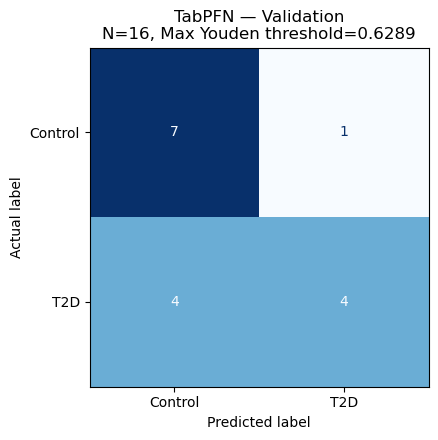

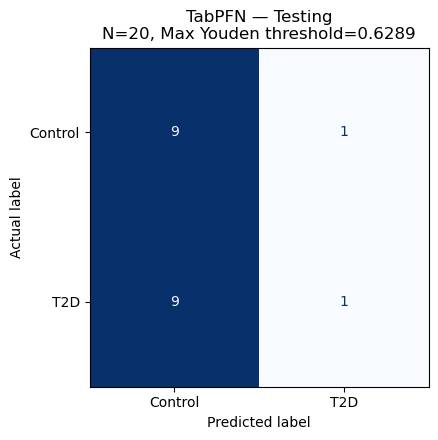

TABPFN — EVALUATION METRICS
Threshold selected from Validation: 0.628906

Performance comparison:


,Validation,Testing
AUC,0.6562,0.5300
Accuracy,0.6875,0.5000
Sensitivity,0.5000,0.1000
Specificity,0.8750,0.9000
Precision,0.8000,0.5000
NPV,0.6364,0.5000
F1_Score,0.6154,0.1667
Youden_Index,0.3750,0.0000
Average_Precision,0.6406,0.5768
Brier_Score,0.2357,0.2546



TABPFN — CONFUSION MATRIX COUNTS


,Dataset,N,Cases,Controls,Threshold,TN,FP,FN,TP
0,validation,16,8,8,0.628906,7,1,4,4
1,testing,20,10,10,0.628906,9,1,9,1



TABPFN EVALUATION COMPLETED
Participants evaluated: 36

Output directory:
Outputs/Step5_TabPFN

Saved files:
 - TabPFN_ConfusionCounts.csv
 - TabPFN_ConfusionMatrix_testing.csv
 - TabPFN_ConfusionMatrix_testing.png
 - TabPFN_ConfusionMatrix_validation.csv
 - TabPFN_ConfusionMatrix_validation.png
 - TabPFN_EvaluationMatrix.csv
 - TabPFN_EvaluationMetrics.csv
 - TabPFN_Predictions.csv
 - TabPFN_RunConfig.json
 - TabPFN_ValidationThresholds.csv


In [5]:
# ============================================================
# 3. TabPFN — Evaluation Metrics and Confusion Matrices
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    brier_score_loss,
)


# ============================================================
# 3.1 Helper Functions
# ============================================================

def safe_divide(numerator, denominator):

    if denominator == 0:
        return np.nan

    return numerator / denominator


def calculate_metrics(
    y_true,
    y_prob,
    threshold
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_prob = np.asarray(
        y_prob,
        dtype=float
    )

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # --------------------------------------------------------
    # Classification metrics
    # --------------------------------------------------------

    sensitivity = safe_divide(
        tp,
        tp + fn
    )

    specificity = safe_divide(
        tn,
        tn + fp
    )

    precision = safe_divide(
        tp,
        tp + fp
    )

    npv = safe_divide(
        tn,
        tn + fn
    )

    accuracy = safe_divide(
        tp + tn,
        len(y_true)
    )

    f1_score = safe_divide(
        2 * tp,
        2 * tp + fp + fn
    )

    youden_index = (
        sensitivity + specificity - 1
    )


    # --------------------------------------------------------
    # Probability-based metrics
    # --------------------------------------------------------

    if len(np.unique(y_true)) == 2:

        auc = roc_auc_score(
            y_true,
            y_prob
        )

        average_precision = average_precision_score(
            y_true,
            y_prob
        )

    else:

        auc = np.nan
        average_precision = np.nan


    brier_score = brier_score_loss(
        y_true,
        y_prob
    )


    # --------------------------------------------------------
    # Return metrics
    # --------------------------------------------------------

    metrics = {

        "N": len(y_true),

        "Cases": int((y_true == 1).sum()),

        "Controls": int((y_true == 0).sum()),

        "Threshold": float(threshold),

        "AUC": auc,

        "Accuracy": accuracy,

        "Sensitivity": sensitivity,

        "Specificity": specificity,

        "Precision": precision,

        "NPV": npv,

        "F1_Score": f1_score,

        "Youden_Index": youden_index,

        "Average_Precision": average_precision,

        "Brier_Score": brier_score,

        "TN": int(tn),

        "FP": int(fp),

        "FN": int(fn),

        "TP": int(tp),

    }

    return metrics, cm


# ============================================================
# 3.2 Evaluate Validation and Testing
# ============================================================

evaluation_records = []

confusion_records = []

for split in [
    "validation",
    "testing"
]:

    subset = prediction_df.loc[
        prediction_df["Dataset"] == split
    ].copy()

    y_true = subset[
        "T2D"
    ].to_numpy(dtype=int)

    y_prob = subset[
        "Predicted_Probability"
    ].to_numpy(dtype=float)

    assert len(y_true) == (
        16 if split == "validation" else 20
    )

    assert np.isfinite(y_prob).all()


    # --------------------------------------------------------
    # Calculate metrics using Validation-selected threshold
    # --------------------------------------------------------

    metrics, cm = calculate_metrics(
        y_true,
        y_prob,
        BEST_THRESHOLD
    )

    metrics["Model"] = "TabPFN"
    metrics["Dataset"] = split

    evaluation_records.append(metrics)


    # --------------------------------------------------------
    # Confusion matrix counts
    # --------------------------------------------------------

    tn, fp, fn, tp = cm.ravel()

    confusion_records.append({

        "Model": "TabPFN",

        "Dataset": split,

        "Threshold": BEST_THRESHOLD,

        "TN": int(tn),

        "FP": int(fp),

        "FN": int(fn),

        "TP": int(tp),

    })


    # --------------------------------------------------------
    # Save confusion matrix counts as CSV
    # --------------------------------------------------------

    cm_df = pd.DataFrame(
        cm,
        index=[
            "Actual_Control",
            "Actual_T2D"
        ],
        columns=[
            "Predicted_Control",
            "Predicted_T2D"
        ]
    )

    cm_df.to_csv(
        OUTPUT_DIR
        / f"TabPFN_ConfusionMatrix_{split}.csv"
    )


    # --------------------------------------------------------
    # Plot confusion matrix
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(5.5, 4.5)
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Control",
            "T2D"
        ]
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(
        f"TabPFN — {split.capitalize()}\n"
        f"N={len(y_true)}, "
        f"Max Youden threshold={BEST_THRESHOLD:.4f}"
    )

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

    plt.tight_layout()

    figure_file = (
        OUTPUT_DIR
        / f"TabPFN_ConfusionMatrix_{split}.png"
    )

    fig.savefig(
        figure_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 3.3 Construct Evaluation DataFrame
# ============================================================

metrics_df = pd.DataFrame(
    evaluation_records
)

metrics_df = (
    metrics_df
    .set_index("Dataset")
    .loc[["validation", "testing"]]
    .reset_index()
)

confusion_df = pd.DataFrame(
    confusion_records
)


# ============================================================
# 3.4 Save Complete Evaluation Results
# ============================================================

metrics_df.to_csv(
    METRICS_FILE,
    index=False
)

confusion_df.to_csv(
    OUTPUT_DIR
    / "TabPFN_ConfusionCounts.csv",
    index=False
)


# ============================================================
# 3.5 Display Evaluation Metrics Matrix
# ============================================================

DISPLAY_METRICS = [
    "AUC",
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "NPV",
    "F1_Score",
    "Youden_Index",
    "Average_Precision",
    "Brier_Score",
]

evaluation_matrix = (
    metrics_df
    .set_index("Dataset")[DISPLAY_METRICS]
    .T
)

evaluation_matrix.columns = [
    "Validation",
    "Testing"
]

# Save original precision
evaluation_matrix.to_csv(
    OUTPUT_DIR
    / "TabPFN_EvaluationMatrix.csv"
)


print("=" * 65)
print("TABPFN — EVALUATION METRICS")
print("=" * 65)

print(
    "Threshold selected from Validation:",
    round(BEST_THRESHOLD, 6)
)

print("\nPerformance comparison:")

display(
    evaluation_matrix.round(4)
)


# ============================================================
# 3.6 Display Confusion Matrix Counts
# ============================================================

print("\n" + "=" * 65)
print("TABPFN — CONFUSION MATRIX COUNTS")
print("=" * 65)

display(
    metrics_df[
        [
            "Dataset",
            "N",
            "Cases",
            "Controls",
            "Threshold",
            "TN",
            "FP",
            "FN",
            "TP",
        ]
    ]
)


# ============================================================
# 3.7 Final Verification
# ============================================================

assert len(metrics_df) == 2

assert set(metrics_df["Dataset"]) == {
    "validation",
    "testing"
}

assert np.allclose(
    metrics_df["Threshold"].to_numpy(),
    BEST_THRESHOLD
)

assert (
    metrics_df[
        ["TN", "FP", "FN", "TP"]
    ].sum(axis=1).to_numpy()
    == metrics_df["N"].to_numpy()
).all()

assert metrics_df.loc[
    metrics_df["Dataset"] == "validation",
    "N"
].iloc[0] == 16

assert metrics_df.loc[
    metrics_df["Dataset"] == "testing",
    "N"
].iloc[0] == 20


# ============================================================
# 3.8 Output Summary
# ============================================================

print("\n" + "=" * 65)
print("TABPFN EVALUATION COMPLETED")
print("=" * 65)

print("Participants evaluated:", len(prediction_df))

print("\nOutput directory:")
print(
    OUTPUT_DIR.relative_to(PROJECT_ROOT)
)

print("\nSaved files:")

for filepath in sorted(
    OUTPUT_DIR.iterdir()
):
    if filepath.is_file():
        print(" -", filepath.name)